# Montaggio del Drive

In [ ]:
!pip install optuna -q

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

**Procedura per cartelle condivise**

Crea un shortcut (scorciatoia) nel tuo Drive.
Questo è il trucco fondamentale per le cartelle condivise:

1. Vai su Google Drive (drive.google.com)

2. Clicca su "Condivisi con me" a sinistra

3. Trova la cartella condivisa (quella del progetto)

4. Tasto destro sulla cartella → "Aggiungi scorciatoia in Drive" (o "Add shortcut to Drive")

5. Clicca "Aggiungi scorciatoia" (la mette in "Il mio Drive") ATTENZIONE NOMINARLO CON LO STESSO NOME DI QUESTO FILE : Codici definitivi_colab

Ora la cartella condivisa appare anche nel tuo "My Drive" personale come una scorciatoia.


# Setup del Percorso di Progetto

In [ ]:
from pathlib import Path

# Verifica che il nome della cartella corrisponda alla tua scorciatoia su Drive

project_path = Path("/content/drive/MyDrive/Codici definitivi_colab")


print("Percorso:", project_path)
print("Esiste?", project_path.exists())
print("\nFile e cartelle che Colab vede:")


for elemento in project_path.iterdir():
    print("-", repr(elemento.name))




Percorso: /content/drive/MyDrive/Codici definitivi_colab
Esiste? True

File e cartelle che Colab vede:
- 'Launcher_colab.ipynb'
- 'MODELLO DEFINITIVO'
- 'modelli'
- 'gestione_launcher'
- 'csv_function'
- 'Analisi_Comparativa'
- 'Data'
- 'nan_and_imputation_function'
- 'risultati_finali'
- 'read_me_vari'
- 'feature_selection_function'
- 'outlier_function'
- 'plotting_function'
- 'Analisi_Dataset'
- 'validation_strategies'
- 'Report_progetto.gdoc'


# PARTE 1 - Esecuzione Preprocessing

In [ ]:
import os
import sys
from pathlib import Path

os.chdir(project_path)
resolved_project_path_str = os.getcwd()
sys.path.insert(0, resolved_project_path_str)

main_file_resolved = Path(resolved_project_path_str) / "gestione_launcher" / "main.py"

print("Directory attuale:", os.getcwd())
print("File da eseguire (resolved):", main_file_resolved)

# Avvia lo script main.py in modalità interattiva
%run -i "{main_file_resolved}"

Directory attuale: /content/drive/.shortcut-targets-by-id/16aa6ebwNmsADfvRbbv7TgGC4aEnarx-H/Codici definitivi
File da eseguire (resolved): /content/drive/.shortcut-targets-by-id/16aa6ebwNmsADfvRbbv7TgGC4aEnarx-H/Codici definitivi/gestione_launcher/main.py
PIPELINE ML - INZIO ESECUZIONE PREPROCESSING DATI

------------------------------------------------------------

[STEP 1] Caricamento ed elaborazione base dei file...

------------------------------------------------------------

[STEP 2] Merge di ICD + Demographic + Triage + BloodTest...

------------------------------------------------------------

[STEP 3 & 4] Pulizia valori impossibili (Triage e BloodTest)...

------------------------------------------------------------

[STEP 5] Calcolo statistiche su BloodTest pulito...

------------------------------------------------------------

[STEP 6] Separazione Feature e Target...
Dimensioni di X (Feature): (3198, 160)
Dimensioni di y (Target): (3198,)

=== MENU DI CONFIGURAZIONE PIPELIN

/usr/local/lib/python3.13/dist-packages/pandas/core/nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


   === Full_Dataset_Unico Completato. Feature finali: 87 ===

------------------------------------------------------------

[STEP 10] Generazione grafici diagnostici...

  Generazione grafici diagnostici in corso...
  Grafici salvati in: risultati_finali/Run_05Sep_1014_Esperimento14/plots

  -> Log creato. Cartella rinominata in: risultati_finali/Run_05Sep_1014_Esperimento14_FullDataset_PreprocessingCompleto

PIPELINE COMPLETATA CON SUCCESSO


# PARTE 2 - Selezione e Validazione del Modello

 ORCHESTRATORE MODELLI - CONFIGURAZIONE INIZIALE

[DOMANDA 1] Modelli disponibili trovati:
   [1] AdaBoost  ->  adaboost_training.py
   [2] DecisionTree  ->  decision_tree_training.py
   [3] KNN  ->  knn_training.py
   [4] RandomForest  ->  randomforest_training.py
   [5] SVM_ECOC_training  ->  SVM_ECOC_training.py
   [6] SVM_standard_training  ->  SVM_standard_training.py
   [7] XGBoost  ->  xgboost_training.py
Scegli il modello da eseguire (1-7): 6

[DOMANDA 2] Scegli la Metrica Primaria per il tuning e l'importanza:
   [1] F1-Score (Bilanciata)
   [2] F2-Score (Pesa maggiormente il Recall - tolleranza Falsi Positivi)
Scegli (1 o 2) [1]: 2

-> [SISTEMA] Metrica primaria bloccata su: F2-Score (macro)

[DOMANDA 3] CV Interna (Tuning)
Vuoi usare K=3 di default? [s/n]: s
-> K interno impostato a: 3

[DOMANDA 4] Fallback Euristico Classe 1
   (Riassegna alla Classe 1 i pazienti per cui il modello è indeciso tra 0 e 2)
Vuoi attivare il Fallback per la Classe 1? [s/n]: s
-> Fallback ATTIVAT

Elaborazione SVM_standard_training:   0%|          | 0/1 [00:00<?, ?it/s]


######################################################################
# AVVIO MODELLO: SVM_STANDARD su Run_30Aug_1739_Esperimento1_KFold_PreprocessingCompleto
######################################################################
-> Metrica: F2-Score (macro)
-> K CV Interna: 3

----------------------------------------------------------------------
LOG ESPERIMENTO: Run_30Aug_1739_Esperimento1_KFold_PreprocessingCompleto
----------------------------------------------------------------------
LOG ESPERIMENTO #1 - 30Aug_1739

Etichetta setup: KFold_PreprocessingCompleto
Strategia Validazione: K-Fold (5 splits)

--- STEP OPZIONALI ---
MAD (outlier univariati): Eseguito
  Soglia Z-Score MAD: 3.5
  Min Osservazioni MAD: 10
DBSCAN (outlier multivariati): Eseguito
  Parametri: eps=1.5, min_samples=10
  Feature set usato: ['temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp']
Imputazione NaN: Eseguita
  Strategia maschera: Opzione 3 (mask_tipici_strict)
  Pool di addestramento (imputer

<Figure size 640x480 with 0 Axes>

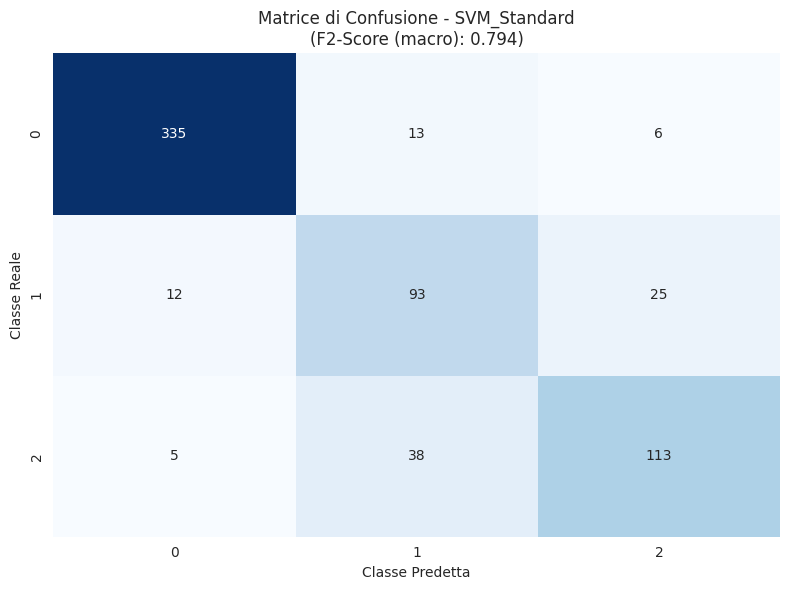

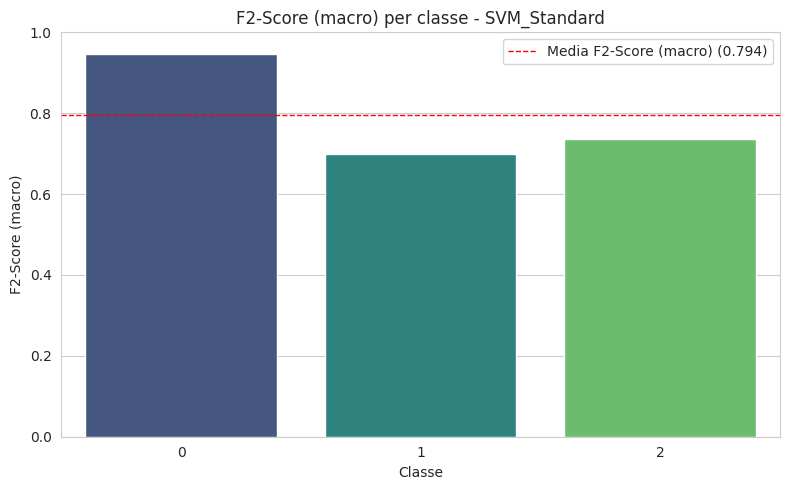


-> Calcolo Permutation Importance sul test del compartimento...

######################################################################
# COMPARTIMENTO: Fold_2
######################################################################
   File X usato: X_train_fs.csv / X_test_fs.csv
   Dimensioni: X_train=(2558, 86), X_test=(640, 86)

[OPTUNA] Avvio ottimizzazione con 20 tentativi (CV interna: 3 fold, metrica: F2-Score (macro))...

 OTTIMIZZAZIONE COMPLETATA
Miglior F2-Score (macro) (CV): 0.7635
Parametri ottimali:
   - C: 1.2452668108659286
   - gamma: auto
   - kernel: rbf

-> Addestramento del modello finale su tutto il train del compartimento...
   [FALLBACK ATTIVO] 16 pazienti ambigui reindirizzati forzatamente alla Classe 1.

 VALUTAZIONE PRESTAZIONI: SVM_Standard

Accuracy               : 0.8094
F2-Score (macro) [*]  : 0.7425   <- metrica primaria (tuning)
F1-Score  (macro)       : 0.7441   (per confronto storico)
Precision (macro)       : 0.7476
Recall    (macro)       : 0.7416
F1-

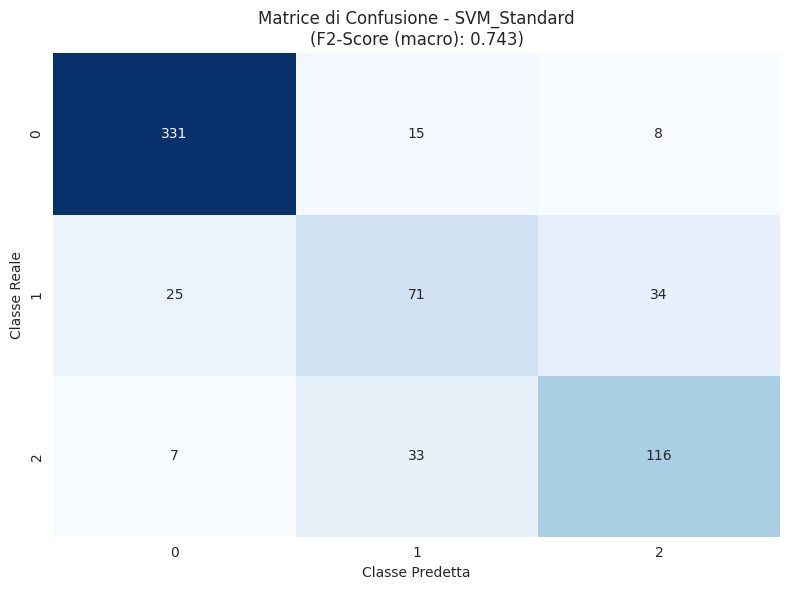

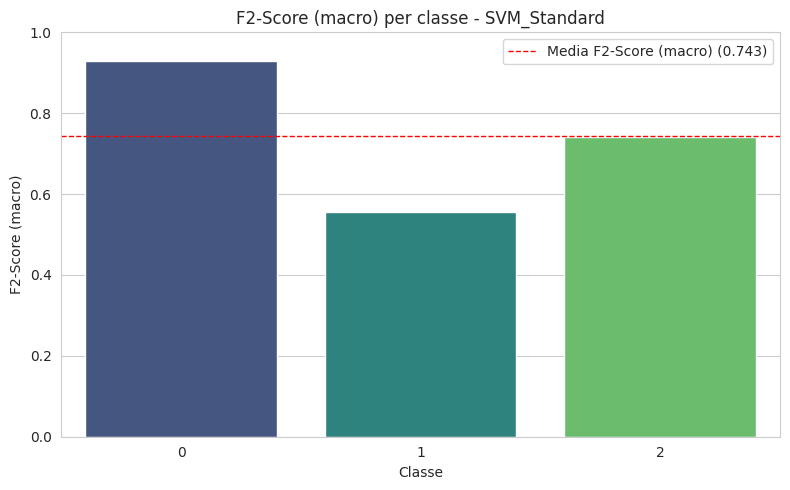


-> Calcolo Permutation Importance sul test del compartimento...

######################################################################
# COMPARTIMENTO: Fold_3
######################################################################
   File X usato: X_train_fs.csv / X_test_fs.csv
   Dimensioni: X_train=(2558, 87), X_test=(640, 87)

[OPTUNA] Avvio ottimizzazione con 20 tentativi (CV interna: 3 fold, metrica: F2-Score (macro))...

 OTTIMIZZAZIONE COMPLETATA
Miglior F2-Score (macro) (CV): 0.7724
Parametri ottimali:
   - C: 1.2915629316911434
   - gamma: auto
   - kernel: rbf

-> Addestramento del modello finale su tutto il train del compartimento...
   [FALLBACK ATTIVO] 32 pazienti ambigui reindirizzati forzatamente alla Classe 1.

 VALUTAZIONE PRESTAZIONI: SVM_Standard

Accuracy               : 0.8063
F2-Score (macro) [*]  : 0.7560   <- metrica primaria (tuning)
F1-Score  (macro)       : 0.7564   (per confronto storico)
Precision (macro)       : 0.7592
Recall    (macro)       : 0.7563
F1-

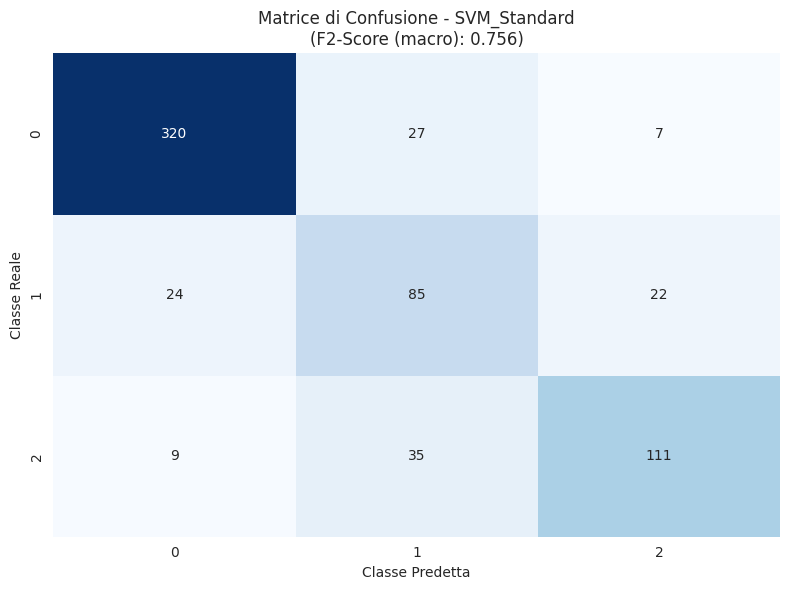

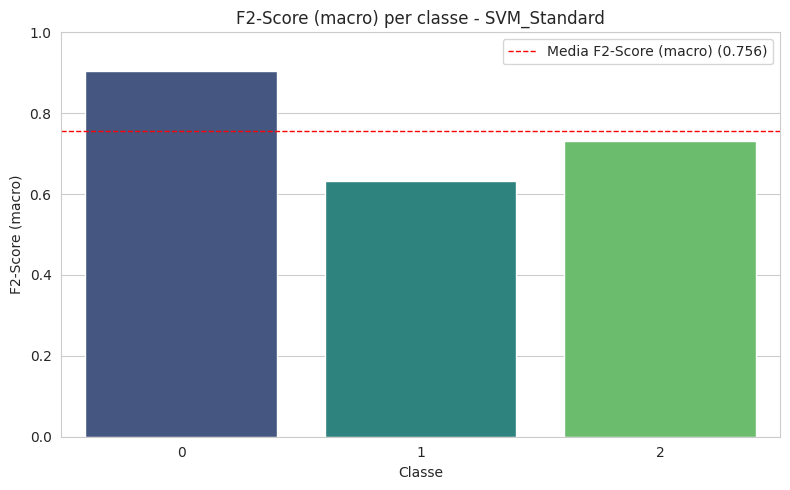


-> Calcolo Permutation Importance sul test del compartimento...

######################################################################
# COMPARTIMENTO: Fold_4
######################################################################
   File X usato: X_train_fs.csv / X_test_fs.csv
   Dimensioni: X_train=(2559, 86), X_test=(639, 86)

[OPTUNA] Avvio ottimizzazione con 20 tentativi (CV interna: 3 fold, metrica: F2-Score (macro))...

 OTTIMIZZAZIONE COMPLETATA
Miglior F2-Score (macro) (CV): 0.7673
Parametri ottimali:
   - C: 1.2316271533908936
   - gamma: auto
   - kernel: rbf

-> Addestramento del modello finale su tutto il train del compartimento...
   [FALLBACK ATTIVO] 19 pazienti ambigui reindirizzati forzatamente alla Classe 1.

 VALUTAZIONE PRESTAZIONI: SVM_Standard

Accuracy               : 0.8310
F2-Score (macro) [*]  : 0.7820   <- metrica primaria (tuning)
F1-Score  (macro)       : 0.7813   (per confronto storico)
Precision (macro)       : 0.7853
Recall    (macro)       : 0.7839
F1-

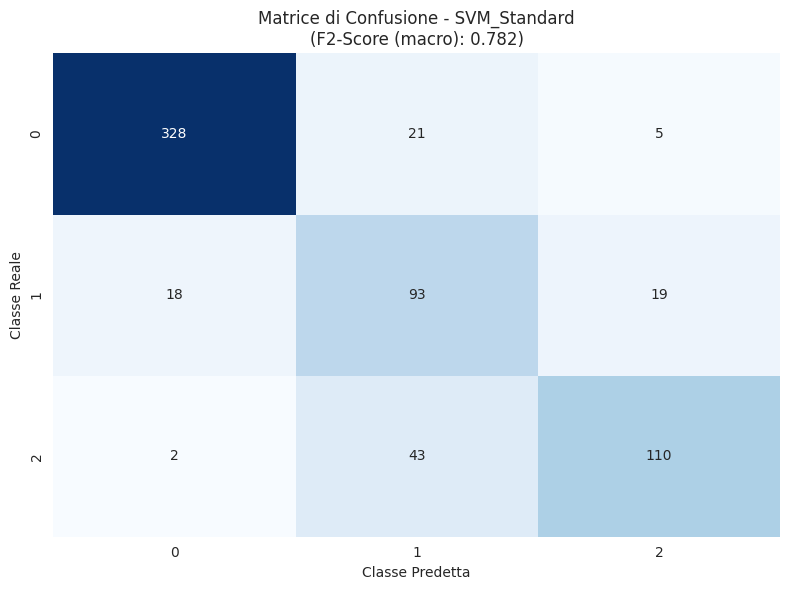

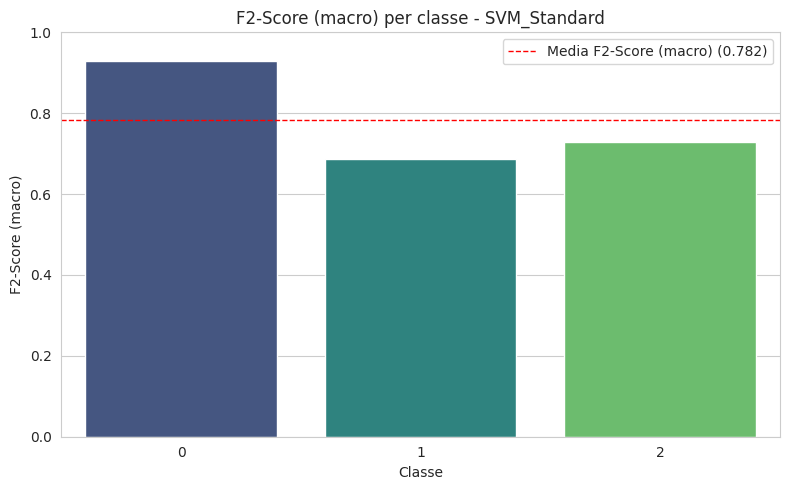


-> Calcolo Permutation Importance sul test del compartimento...

######################################################################
# COMPARTIMENTO: Fold_5
######################################################################
   File X usato: X_train_fs.csv / X_test_fs.csv
   Dimensioni: X_train=(2559, 86), X_test=(639, 86)

[OPTUNA] Avvio ottimizzazione con 20 tentativi (CV interna: 3 fold, metrica: F2-Score (macro))...

 OTTIMIZZAZIONE COMPLETATA
Miglior F2-Score (macro) (CV): 0.7544
Parametri ottimali:
   - C: 0.8564469421875482
   - gamma: scale
   - kernel: rbf

-> Addestramento del modello finale su tutto il train del compartimento...
   [FALLBACK ATTIVO] 21 pazienti ambigui reindirizzati forzatamente alla Classe 1.

 VALUTAZIONE PRESTAZIONI: SVM_Standard

Accuracy               : 0.8106
F2-Score (macro) [*]  : 0.7535   <- metrica primaria (tuning)
F1-Score  (macro)       : 0.7515   (per confronto storico)
Precision (macro)       : 0.7519
Recall    (macro)       : 0.7559
F1

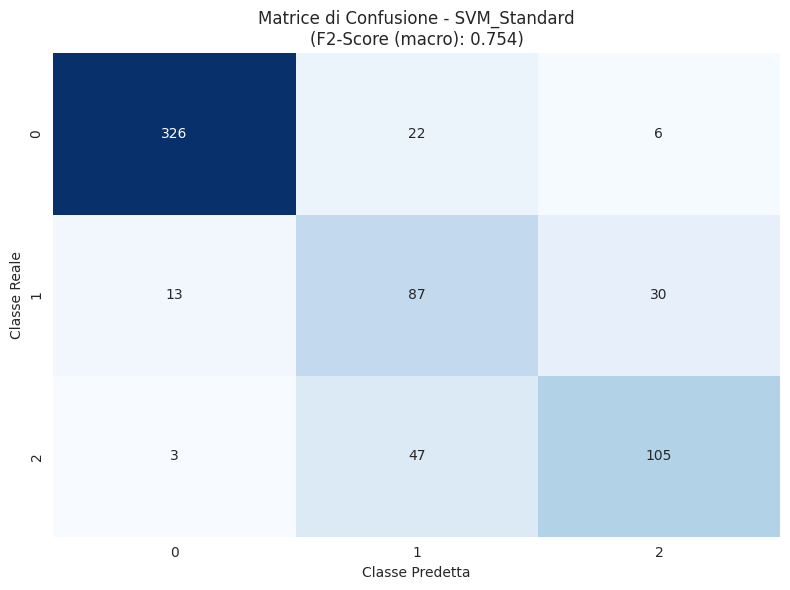

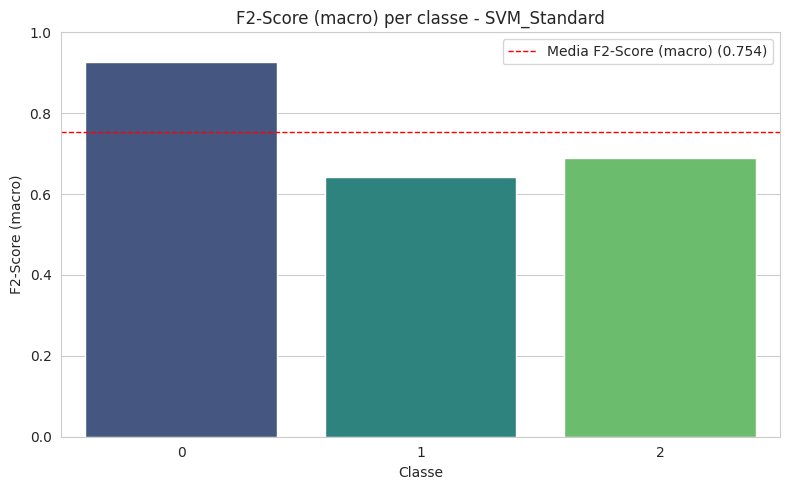


-> Calcolo Permutation Importance sul test del compartimento...

 RISULTATI AGGREGATI - SVM_Standard (5 compartimento/i)
   Accuracy            : 0.8205 +/- 0.0170
   F_Target_macro      : 0.7657 +/- 0.0216
   F1_macro            : 0.7654 +/- 0.0211
   Precision_macro     : 0.7676 +/- 0.0208
   Recall_macro        : 0.7666 +/- 0.0222
   F1_weighted         : 0.8220 +/- 0.0175
   Precision_weighted  : 0.8258 +/- 0.0190
   Recall_weighted     : 0.8205 +/- 0.0170

-> Salvato: risultati_per_compartimento_SVM_Standard.csv
   -> Salvati: feature_importance_SVM_Standard.png / .csv


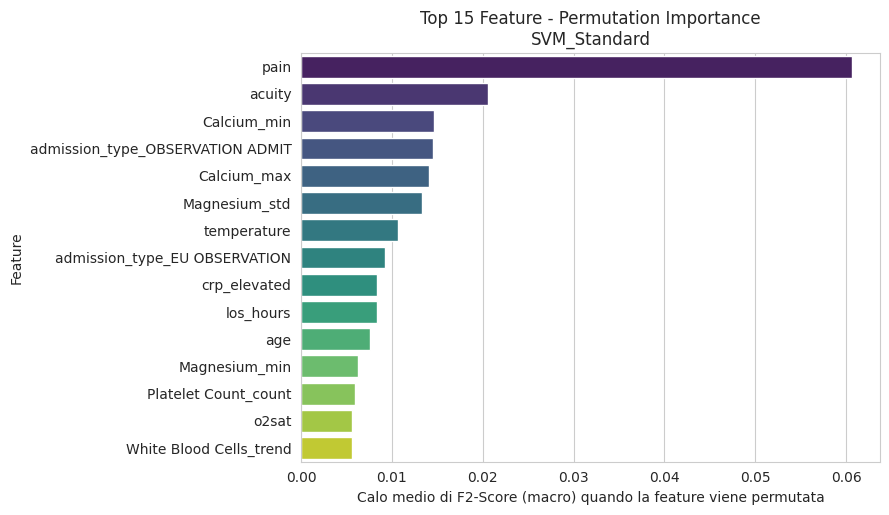


------------------------------------------------------------
 IPERPARAMETRI SCELTI PER COMPARTIMENTO
------------------------------------------------------------
Compartimento        C gamma kernel  F2-Score (macro)_CV_train
       Fold_1 2.801635  auto    rbf                   0.745036
       Fold_2 1.245267  auto    rbf                   0.763472
       Fold_3 1.291563  auto    rbf                   0.772387
       Fold_4 1.231627  auto    rbf                   0.767285
       Fold_5 0.856447 scale    rbf                   0.754403

-> Salvato: iperparametri_per_compartimento.csv

SCRIPT SVM_Standard COMPLETATO
Risultati completi in: /content/drive/.shortcut-targets-by-id/16aa6ebwNmsADfvRbbv7TgGC4aEnarx-H/Codici definitivi/risultati_finali/Run_30Aug_1739_Esperimento1_KFold_PreprocessingCompleto/Risultati_SVM_Standard_F2_Fallback

 RIEPILOGO FINALE BATCH - SVM_standard_training
Esperimenti totali      : 1
Completati con successo : 1
Saltati / Falliti       : 0

--- COMPLETATI ---
  [

In [ ]:
import os
import sys
from pathlib import Path

%matplotlib inline

os.chdir(project_path)
resolved_project_path_str = os.getcwd()
sys.path.insert(0, resolved_project_path_str)

# Importa il nuovo orchestratore centralizzato
from modelli.gestione_modelli import avvia_pipeline_completa

# Avvia il flusso interattivo
avvia_pipeline_completa()

# PARTE 3 - Classificazione Gerarchica

In [ ]:
import os
import sys
from pathlib import Path

# Assicurati che Colab sia posizionato nella root del progetto
os.chdir(project_path)
resolved_project_path_str = os.getcwd()
sys.path.insert(0, resolved_project_path_str)

# Importa la funzione principale della cascata
from modelli.esegui_cascata import avvia_cascata

# Avvia l'architettura gerarchica interattiva
avvia_cascata()

 🚀 AVVIO ARCHITETTURA AVANZATA: HIERARCHICAL CASCADE UNIVERSALE

[DOMANDA 1] Trovati 13 esperimenti in 'risultati_finali/':
   [1] Run_05Sep_1014_Esperimento14_FullDataset_PreprocessingCompleto
   [2] Run_30Aug_1739_Esperimento1_KFold_PreprocessingCompleto
   [3] Run_30Aug_1901_Esperimento2_PreprocessingCompleto
   [4] Run_30Aug_1931_Esperimento3_KFold_PreprocessingAlternativo(No MAD, No DBSCAN, No FeatureSelection)
   [5] Run_30Aug_1933_Esperimento4_PreprocessingAlternativo(No MAD, No DBSCAN, No FeatureSelection)
   [6] Run_30Aug_1940_Esperimento5_KFold_PreprocessingSemplice
   [7] Run_30Aug_1941_Esperimento6_PreprocessingSemplice
   [8] Run_31Aug_1334_Esperimento7_Bootstrap_PreprocessingAlternativo(No MAD, No DBSCAN, No FeatureSelection)
   [9] Run_31Aug_1337_Esperimento8_Bootstrap_PreprocessingAlternativo(No DBSCAN)
   [10] Run_31Aug_1340_Esperimento9_Bootstrap_PreprocessingCompleto
   [11] Run_31Aug_1346_Esperimento10_Bootstrap_PreprocessingSemplice
   [12] Run_31Aug_1624_Esperimen

Elaborazione SVM_Cascata:   0%|          | 0/1 [00:00<?, ?it/s]

[I 2026-09-05 16:31:00,583] A new study created in memory with name: no-name-2a69abdd-b69f-4aab-b3ee-f489038533d1



**********************************************************************
*** ELABORAZIONE ESPERIMENTO: Run_30Aug_1739_Esperimento1_KFold_PreprocessingCompleto ***
**********************************************************************

-> Strategia rilevata: K-FOLD ESTERNO (5 compartimenti)

############################################################
# COMPARTIMENTO: Fold_1
############################################################
   File X usato: X_train_fs.csv / X_test_fs.csv
   Dimensioni: X_train=(2558, 89), X_test=(640, 89)

--- FASE A: Addestramento Modello (Classe 0 vs Classe 1+2) ---
   [!] Lancio Optuna (SVM) per MODELLO A (20 trials)...
   >>> MODELLO A - Miglior Score CV: 0.9201

--- FASE B: Addestramento Modello (Classe 1 vs Classe 2) ---
   -> Bilanciamento SVM: class_weight='balanced' attivato
   [!] Lancio Optuna (SVM) per MODELLO B (20 trials)...
   >>> MODELLO B - Miglior Score CV: 0.7452


# PARTE 4 - Analisi Comparativa Globale

AVVIO MASTER AGGREGATOR - CONFRONTO ESPERIMENTI E MODELLI
-> Eseguo: master_aggregator.py


 🏆 RISULTATI ANALISI COMPARATIVA 🏆

🏆 TOP 3 MODELLI F1 (Massima Precisione Globale) 🏆
XGBoost_F1 | F1: 0.7836 (±0.0166) | Exp 1 (KFold_PreprocessingCompleto)
XGBoost_F1 | F1: 0.7834 (±0.0073) | Exp 5 (KFold_PreprocessingSemplice)
XGBoost_F1 | F1: 0.7773 (±0.0000) | Exp 9 (Bootstrap_PreprocessingCompleto)

🏆 TOP 3 MODELLI F2 (Ottimizzati per Sensibilità Clinica) 🏆
XGBoost_F2_Fallback | F2: 0.7876 (±0.0265) | Exp 1 (KFold_PreprocessingCompleto)
XGBoost_Cascata_F2 | F2: 0.7825 (±0.0181) | Exp 1 (KFold_PreprocessingCompleto)
XGBoost_F2 | F2: 0.7794 (±0.0214) | Exp 1 (KFold_PreprocessingCompleto)

⚖️ TOP 3 SCELTE BILANCIATE (Miglior F2 con F1 >= 0.7428) ⚖️
XGBoost_F2_Fallback | F2: 0.7876 (±0.0265) (F1: 0.7895) | Exp 1 (KFold_PreprocessingCompleto)
XGBoost_Cascata_F2 | F2: 0.7825 (±0.0181) (F1: 0.7834) | Exp 1 (KFold_PreprocessingCompleto)
XGBoost_F2 | F2: 0.7794 (±0.0214) (F1: 0.7821) | Exp 1 (KFold

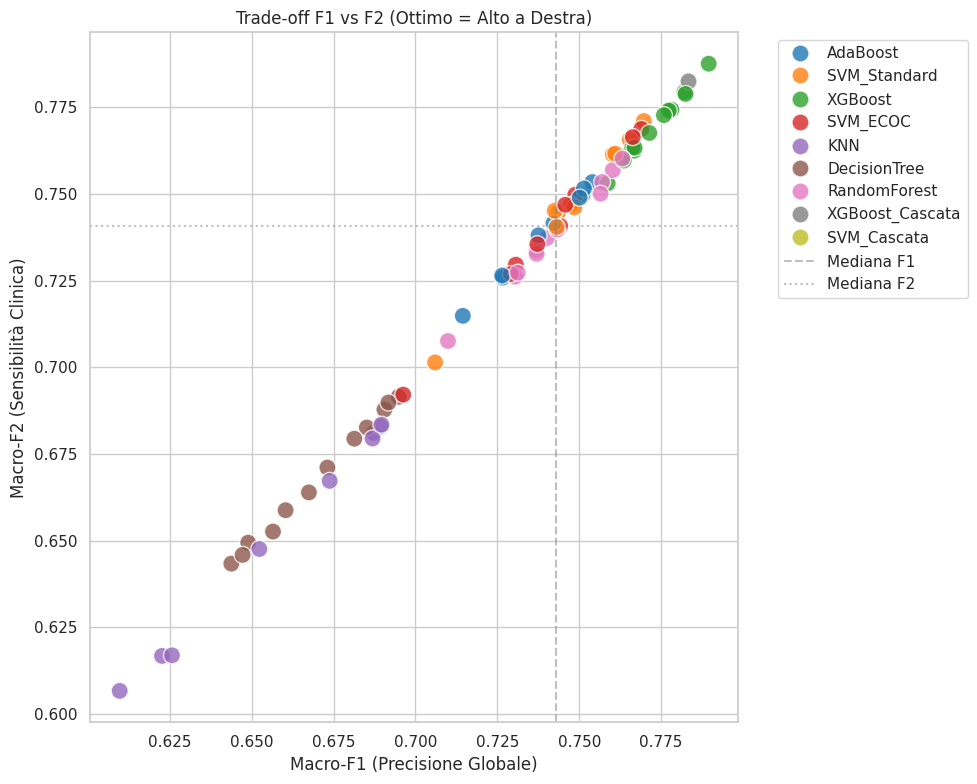

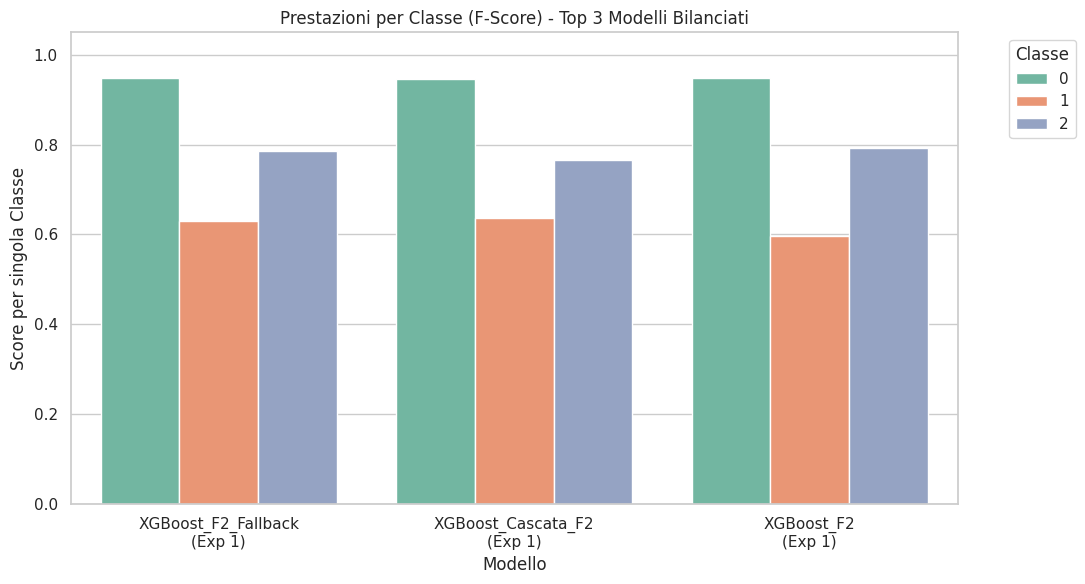


✅ Salvataggio completato in: /content/drive/.shortcut-targets-by-id/16aa6ebwNmsADfvRbbv7TgGC4aEnarx-H/Codici definitivi/Analisi_Comparativa



<Figure size 640x480 with 0 Axes>

In [ ]:
import os
import sys
from pathlib import Path

%matplotlib inline

os.chdir(project_path)
resolved_project_path_str = os.getcwd()
sys.path.insert(0, resolved_project_path_str)

# Verifica che lo script esista nella cartella del progetto
aggregator_script = Path(resolved_project_path_str) / "gestione_launcher" / "master_aggregator.py"

if aggregator_script.is_file():
    print("=" * 70)
    print("AVVIO MASTER AGGREGATOR - CONFRONTO ESPERIMENTI E MODELLI")
    print("=" * 70)
    print(f"-> Eseguo: {aggregator_script.name}\n")

    # Esegue lo script all'interno dell'ambiente Colab
    %run -i "{aggregator_script}"

    # Stampa a schermo il contenuto del file VINCITORE_ASSOLUTO.txt appena generato
    out_dir = Path(resolved_project_path_str) / "Analisi_Comparativa"
    file_vincitore = out_dir / "VINCITORE_ASSOLUTO.txt"

    if file_vincitore.exists():
        print("\n" + "*" * 60)
        with open(file_vincitore, "r", encoding="utf-8") as f:
            print(f.read())
        print("*" * 60)
        print("\n-> NOTA: Controlla la cartella 'Analisi_Comparativa' nel tuo Drive per visualizzare i grafici generati (Barplot, Boxplot e Heatmap).")
else:
    print(f"\n[ERRORE] Il file '{aggregator_script.name}' non è stato trovato.")
    print("Assicurati di aver salvato il file master_aggregator.py nella cartella principale del progetto su Drive.")

# PARTE 5 - Esportazione Modello Definitivo

In [ ]:
import os
import sys
from pathlib import Path

os.chdir(project_path)
resolved_project_path_str = os.getcwd()
sys.path.insert(0, resolved_project_path_str)

script_esportazione = Path(resolved_project_path_str) / "gestione_launcher" / "esporta_modello.py"

if script_esportazione.is_file():
    %run -i "{script_esportazione}"
else:
    print(f"\n[ERRORE] Il file '{script_esportazione.name}' non è stato trovato.")

 🧠 ESPORTATORE UNIVERSALE MODELLO CLINICO DEFINITIVO (RE-FIT 100%)

[DOMANDA 1] Seleziona l'esperimento (Dataset) da usare per l'esportazione:
   [1] Run_05Sep_1014_Esperimento14_FullDataset_PreprocessingCompleto
   [2] Run_30Aug_1739_Esperimento1_KFold_PreprocessingCompleto
   [3] Run_30Aug_1901_Esperimento2_PreprocessingCompleto
   [4] Run_30Aug_1931_Esperimento3_KFold_PreprocessingAlternativo(No MAD, No DBSCAN, No FeatureSelection)
   [5] Run_30Aug_1933_Esperimento4_PreprocessingAlternativo(No MAD, No DBSCAN, No FeatureSelection)
   [6] Run_30Aug_1940_Esperimento5_KFold_PreprocessingSemplice
   [7] Run_30Aug_1941_Esperimento6_PreprocessingSemplice
   [8] Run_31Aug_1334_Esperimento7_Bootstrap_PreprocessingAlternativo(No MAD, No DBSCAN, No FeatureSelection)
   [9] Run_31Aug_1337_Esperimento8_Bootstrap_PreprocessingAlternativo(No DBSCAN)
   [10] Run_31Aug_1340_Esperimento9_Bootstrap_PreprocessingCompleto
   [11] Run_31Aug_1346_Esperimento10_Bootstrap_PreprocessingSemplice
   [12] Run_3